# Лабораторная работа №2 — Классификация и нейронные сети

**Датасет:** Wine Quality (красное вино) · **Задача:** многоклассовая классификация качества вина · **Классы:** 3, 4, 5, 6, 7, 8.

**Цель:** изучить пять семейств методов классификации Scikit-Learn, исследовать дисбаланс классов и SMOTE, сравнить метрики, подобрать гиперпараметры, обучить многослойную нейросеть TensorFlow/Keras и визуализировать обучение в TensorBoard.

**Порядок:** запускайте ноутбук сверху вниз. Сначала выполняется автоматическая проверка библиотек; затем вывод каждого блока сопровождается интерпретацией. Для полной проверки выполните **Run All** в VS Code. Первый запуск может устанавливать пакеты из интернета и обучать модели.

**Методическое правило:** синтетические объекты SMOTE создаются *только на тренировочных данных*, внутри CV; тестовая выборка никогда не изменяется.

**TensorBoard включён прямо в ноутбук:** раздел 8.1 использует Jupyter-расширение и показывает интерактивную панель под кодовой ячейкой.


> **Для повторной сдачи.** Эта версия основана на твоём ранее **выполненном** ноутбуке: численные результаты и графики TensorFlow получены при запуске на твоём Windows (2 ноября 2026 года), а не созданы искусственно. Перед повторной отправкой на GitHub осталось встроить **настоящий скриншот TensorBoard** в раздел 8.1, проверить вывод разделов 7–9 и сохранить файл через Ctrl+S. При повторном `Run All` результаты могут немного измениться.

## 0. Проверка и установка зависимостей

Первая ячейка автоматически проверяет библиотеки **в том же интерпретаторе Python, который выбран в VS Code в качестве Jupyter Kernel**. Если чего-то не хватает, выполняется установка через `python -m pip`. Для установки при первом запуске нужен интернет. TensorFlow обязателен: при его отсутствии работа **не пропустит** нейросеть молча. Если Python сообщает об установке обновлённых пакетов, иногда требуется перезапуск ядра и повторный `Run All`.

In [1]:
import sys, subprocess, importlib.util, platform
print('Python:', sys.version.split()[0], '|', sys.executable)
print('ОС:', platform.platform())
packages = {'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib',
            'seaborn':'seaborn','sklearn':'scikit-learn',
            'imblearn':'imbalanced-learn','scipy':'scipy',
            'IPython':'ipython','tensorflow':'tensorflow','tensorboard':'tensorboard'}
missing = [pkg for mod, pkg in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Устанавливаем:', ', '.join(missing))
    proc = subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], text=True,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(proc.stdout[-4500:])
    if proc.returncode:
        raise RuntimeError('Установка завершилась ошибкой. Проверьте интернет, версию Python и текст выше. '
                           'Для Windows рекомендуется Python 3.11/3.12 и новое виртуальное окружение.')
else:
    print('Все необходимые библиотеки уже установлены.')
import tensorflow as tf
print('TensorFlow:', tf.__version__, '| Устройства:', tf.config.list_physical_devices())
print('✓ TensorFlow доступен, нейросетевой блок будет выполнен.')

Python: 3.13.2 | c:\Users\Perfect_Player\AppData\Local\Programs\Python\Python313\python.exe
ОС: Windows-11-10.0.26200-SP0
Все необходимые библиотеки уже установлены.


TensorFlow: 2.21.0 | Устройства: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
✓ TensorFlow доступен, нейросетевой блок будет выполнен.


**Интерпретация:** строка `✓ TensorFlow доступен` означает, что установка прошла успешно. Работа на CPU допустима; GPU для этой небольшой таблицы не требуется. Если возникла ошибка установки, ноутбук останавливается на ней, не выдавая незавершённую работу за готовую.

## 1. Импорт библиотек и воспроизводимость

In [2]:
import os, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Binarizer, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SKPipeline
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
SEED=42
os.environ['PYTHONHASHSEED']=str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid',palette='deep')
plt.rcParams['figure.dpi']=110
print('Импорты успешны; seed =',SEED)

Импорты успешны; seed = 42


**Вывод:** одинаковый `SEED` помогает повторять эксперименты, хотя отдельные низкоуровневые операции нейросети могут оставаться недетерминированными.

## 2. Загрузка датасета и первичная проверка

In [3]:
path=Path('winequality-red.csv')
if not path.exists():
    raise FileNotFoundError('Положите winequality-red.csv рядом с этим .ipynb. Рабочая папка: '+str(Path.cwd()))
df=pd.read_csv(path,sep=';')
if df.shape[1]==1: df=pd.read_csv(path)  # на случай файла с другим разделителем
print('Размер исходного набора:',df.shape)
print('Колонки:',list(df.columns))
display(df.head())
display(df.dtypes.to_frame('Тип'))
print('Пропуски по столбцам:'); display(df.isna().sum().to_frame('Пропуски'))
print('Количество полных дубликатов:',int(df.duplicated().sum()))

Размер исходного набора: (1599, 12)
Колонки: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


,Тип
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


Пропуски по столбцам:


,Пропуски
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Количество полных дубликатов: 240


**Объяснение:** исходно 1599 строк и 12 колонок. `quality` является целевой переменной, остальные 11 числовых столбцов — признаки. Пропуски проверяются методом `isna`, дубликаты — `duplicated`.

После очистки: (1359, 12) | X: (1359, 11) | y: (1359,) | классы: [3 4 5 6 7 8]


,Объекты
Класс,
3,10
4,53
5,577
6,535
7,167
8,17


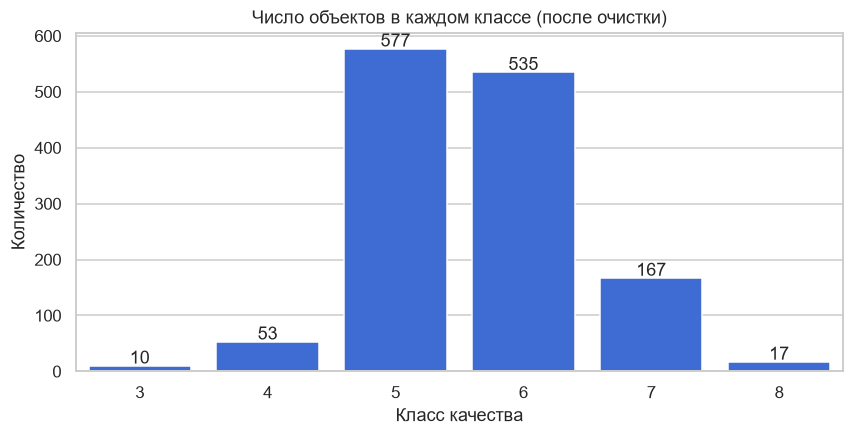

In [4]:
df_clean=df.dropna().drop_duplicates().reset_index(drop=True)
X=df_clean.drop(columns=['quality'])
y=df_clean['quality'].astype(int)
classes=np.sort(y.unique())
counts=y.value_counts().reindex(classes,fill_value=0)
print('После очистки:',df_clean.shape,'| X:',X.shape,'| y:',y.shape,'| классы:',classes)
display(counts.rename_axis('Класс').to_frame('Объекты'))
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(x=counts.index.astype(str),y=counts.values,ax=ax,color='#2563eb')
for i,c in enumerate(counts): ax.text(i,c+4,str(c),ha='center')
ax.set(title='Число объектов в каждом классе (после очистки)',xlabel='Класс качества',ylabel='Количество')
plt.show()

**Вывод:** классы 5 и 6 доминируют, а классы 3 и 8 очень редки. Одной Accuracy недостаточно для объективной оценки. Далее используем **macro F1** и отдельно изучаем влияние SMOTE на редкие классы.

## 3. Разделение Train / Test и демонстрация SMOTE

Train: (1087, 11) Test: (272, 11)


,Train,Test
quality,,
3,8,2
4,42,11
5,461,116
6,428,107
7,134,33
8,14,3


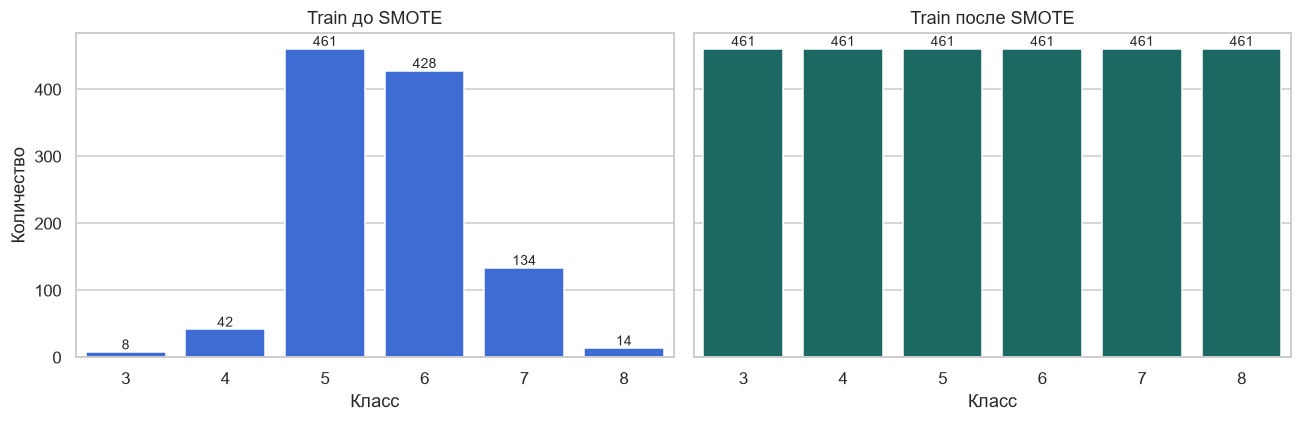

Распределение TEST не менялось: {3: 2, 4: 11, 5: 116, 6: 107, 7: 33, 8: 3}


In [5]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,
                                        stratify=y,random_state=SEED)
print('Train:',X_train.shape,'Test:',X_test.shape)
display(pd.DataFrame({'Train':y_train.value_counts().reindex(classes),
                      'Test':y_test.value_counts().reindex(classes)}))
scaler_demo=StandardScaler()
X_train_std=scaler_demo.fit_transform(X_train)
smote_demo=SMOTE(random_state=SEED,k_neighbors=3)
X_synth,y_synth=smote_demo.fit_resample(X_train_std,y_train)
counts_before=y_train.value_counts().reindex(classes)
counts_after=pd.Series(y_synth).value_counts().reindex(classes)
fig,axs=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,cc,title,color in [(axs[0],counts_before,'Train до SMOTE','#2563eb'),
                          (axs[1],counts_after,'Train после SMOTE','#0f766e')]:
    sns.barplot(x=cc.index.astype(str),y=cc.values,ax=ax,color=color)
    for i,v in enumerate(cc.values):ax.text(i,v+4,str(v),ha='center',fontsize=9)
    ax.set(title=title,xlabel='Класс',ylabel='Количество')
plt.tight_layout();plt.show()
print('Распределение TEST не менялось:',y_test.value_counts().sort_index().to_dict())

**Что делает SMOTE?** Берёт близких соседей **одного класса** и создаёт между ними синтетическую точку: `x_new = x_i + λ(x_neighbor − x_i)`, где `λ ∈ [0,1]`. Балансировка на графике служит **демонстрацией**; для обучения моделей ниже создаётся *новый SMOTE внутри каждого тренировочного fold* через `imblearn.Pipeline`. Это важно для предотвращения утечки данных. Синтетические записи не заменяют реальные независимые измерения.

## 4. Пять семейств классификаторов и сетки гиперпараметров

Включены **4 разновидности Naive Bayes**, Decision Tree, LDA, SVM и kNN. Для Multinomial/Complement входные признаки преобразуются к неотрицательной шкале (MinMax), для Bernoulli — в бинарные признаки. Для SVM и kNN используется StandardScaler. Обработка помещена в Pipeline.

In [6]:
def build_pipeline(name,use_smote):
    steps=[('imputer',SimpleImputer(strategy='median'))]
    if name in ['GaussianNB','Decision Tree','LDA','SVM','kNN']:
        steps.append(('scale',StandardScaler()))
    elif name in ['MultinomialNB','ComplementNB','BernoulliNB']:
        steps.append(('scale',MinMaxScaler()))
    if name=='BernoulliNB':
        steps.append(('binary',Binarizer(threshold=0.5)))
    if use_smote: steps.append(('smote',SMOTE(random_state=SEED,k_neighbors=3)))
    models={'GaussianNB':GaussianNB(),
            'MultinomialNB':MultinomialNB(),
            'ComplementNB':ComplementNB(),
            'BernoulliNB':BernoulliNB(),
            'Decision Tree':DecisionTreeClassifier(random_state=SEED),
            'LDA':LinearDiscriminantAnalysis(solver='lsqr'),
            'SVM':SVC(probability=True,random_state=SEED),
            'kNN':KNeighborsClassifier()}
    steps.append(('model',models[name]))
    return Pipeline(steps)

param_grids={
 'GaussianNB':{'model__var_smoothing':[1e-9,1e-7,1e-5]},
 'MultinomialNB':{'model__alpha':[0.1,1.0,5.0]},
 'ComplementNB':{'model__alpha':[0.1,1.0,5.0]},
 'BernoulliNB':{'model__alpha':[0.1,1.0,5.0]},
 'Decision Tree':{'model__max_depth':[4,8,12], 'model__min_samples_leaf':[2,8],
                  'model__criterion':['gini','entropy']},
 'LDA':{'model__shrinkage':[None,'auto',0.3]},
 'SVM':{'model__C':[0.3,3,10], 'model__gamma':['scale','auto'], 'model__kernel':['rbf']},
 'kNN':{'model__n_neighbors':[3,9,17], 'model__weights':['uniform','distance'],
        'model__p':[1,2]}}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
display(pd.DataFrame([{'Алгоритм':k,'Сетка':str(v)} for k,v in param_grids.items()]))

,Алгоритм,Сетка
0,GaussianNB,"{'model__var_smoothing': [1e-09, 1e-07, 1e-05]}"
1,MultinomialNB,"{'model__alpha': [0.1, 1.0, 5.0]}"
2,ComplementNB,"{'model__alpha': [0.1, 1.0, 5.0]}"
3,BernoulliNB,"{'model__alpha': [0.1, 1.0, 5.0]}"
4,Decision Tree,"{'model__max_depth': [4, 8, 12], 'model__min_s..."
5,LDA,"{'model__shrinkage': [None, 'auto', 0.3]}"
6,SVM,"{'model__C': [0.3, 3, 10], 'model__gamma': ['s..."
7,kNN,"{'model__n_neighbors': [3, 9, 17], 'model__wei..."


**Разбор:** параметр `C` регулирует строгость SVM, `gamma` влияет на RBF-границу, `max_depth` ограничивает дерево, `n_neighbors` задаёт число соседей kNN, `alpha` регулирует сглаживание NB, `shrinkage` стабилизирует ковариацию LDA. Основная метрика подбора — `f1_macro`, чтобы учитывать все шесть классов.

## 5. Подбор гиперпараметров и сравнение до/после SMOTE

Для каждого алгоритма исследуются два режима. Пятикратная CV проводится **только на Train**. На каждом fold SMOTE видит лишь обучающую часть; Test остаётся независимым. Этот блок может выполняться несколько минут.

In [7]:
searches={}; rows=[]; test_predictions={}; test_probabilities={}
for name,grid in param_grids.items():
    for use_smote in [False,True]:
        mode='SMOTE' if use_smote else 'Без SMOTE'
        search=GridSearchCV(build_pipeline(name,use_smote),grid,
                            cv=cv,scoring='f1_macro',n_jobs=-1,refit=True,error_score='raise')
        search.fit(X_train,y_train)
        model=search.best_estimator_
        pred=model.predict(X_test)
        proba=model.predict_proba(X_test)
        test_predictions[(name,mode)]=pred
        test_probabilities[(name,mode)]=proba
        searches[(name,mode)]=search
        rows.append({'Алгоритм':name,'Режим':mode,'CV F1 macro':search.best_score_,
                     'Accuracy':accuracy_score(y_test,pred),
                     'Precision macro':precision_score(y_test,pred,average='macro',zero_division=0),
                     'Recall macro':recall_score(y_test,pred,average='macro',zero_division=0),
                     'F1 macro':f1_score(y_test,pred,average='macro',zero_division=0),
                     'AUC ROC OvR macro':roc_auc_score(y_test,proba,labels=classes,
                                                        multi_class='ovr',average='macro'),
                     'Лучшие параметры':search.best_params_})
        print(f'{name:16} {mode:9} CV macro F1={search.best_score_:.3f} | Test macro F1={rows[-1]["F1 macro"]:.3f}')
results=pd.DataFrame(rows).sort_values('F1 macro',ascending=False).reset_index(drop=True)
display(results.round(3))

GaussianNB       Без SMOTE CV macro F1=0.347 | Test macro F1=0.295
GaussianNB       SMOTE     CV macro F1=0.220 | Test macro F1=0.178
MultinomialNB    Без SMOTE CV macro F1=0.187 | Test macro F1=0.187
MultinomialNB    SMOTE     CV macro F1=0.233 | Test macro F1=0.219
ComplementNB     Без SMOTE CV macro F1=0.238 | Test macro F1=0.229
ComplementNB     SMOTE     CV macro F1=0.140 | Test macro F1=0.140
BernoulliNB      Без SMOTE CV macro F1=0.209 | Test macro F1=0.221
BernoulliNB      SMOTE     CV macro F1=0.206 | Test macro F1=0.147
Decision Tree    Без SMOTE CV macro F1=0.287 | Test macro F1=0.257
Decision Tree    SMOTE     CV macro F1=0.279 | Test macro F1=0.190
LDA              Без SMOTE CV macro F1=0.323 | Test macro F1=0.282
LDA              SMOTE     CV macro F1=0.289 | Test macro F1=0.240


c:\Users\Perfect_Player\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM              Без SMOTE CV macro F1=0.288 | Test macro F1=0.290


c:\Users\Perfect_Player\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM              SMOTE     CV macro F1=0.311 | Test macro F1=0.300
kNN              Без SMOTE CV macro F1=0.331 | Test macro F1=0.282
kNN              SMOTE     CV macro F1=0.314 | Test macro F1=0.267


,Алгоритм,Режим,CV F1 macro,Accuracy,Precision macro,Recall macro,F1 macro,AUC ROC OvR macro,Лучшие параметры
0,SVM,SMOTE,0.311,0.526,0.296,0.324,0.300,0.701,"{'model__C': 10, 'model__gamma': 'auto', 'mode..."
1,GaussianNB,Без SMOTE,0.347,0.544,0.292,0.301,0.295,0.689,{'model__var_smoothing': 1e-09}
2,SVM,Без SMOTE,0.288,0.599,0.289,0.293,0.290,0.802,"{'model__C': 10, 'model__gamma': 'scale', 'mod..."
3,kNN,Без SMOTE,0.331,0.537,0.281,0.288,0.282,0.639,"{'model__n_neighbors': 3, 'model__p': 2, 'mode..."
4,LDA,Без SMOTE,0.323,0.585,0.287,0.283,0.282,0.776,{'model__shrinkage': 0.3}
5,kNN,SMOTE,0.314,0.452,0.273,0.305,0.267,0.617,"{'model__n_neighbors': 3, 'model__p': 2, 'mode..."
6,Decision Tree,Без SMOTE,0.287,0.522,0.253,0.261,0.257,0.564,"{'model__criterion': 'entropy', 'model__max_de..."
7,LDA,SMOTE,0.289,0.404,0.274,0.250,0.240,0.720,{'model__shrinkage': None}
8,ComplementNB,Без SMOTE,0.238,0.515,0.232,0.249,0.229,0.715,{'model__alpha': 1.0}
9,BernoulliNB,Без SMOTE,0.209,0.533,0.260,0.229,0.221,0.684,{'model__alpha': 0.1}


**Вывод:** таблица позволяет сравнить модели и варианты SMOTE по нескольким метрикам. SMOTE **не гарантирует** роста Accuracy или F1: он перераспределяет акцент обучения на редкие классы. CV F1 используется для подбора модели; итоговые Test-метрики вычисляются только на исходных тестовых объектах.

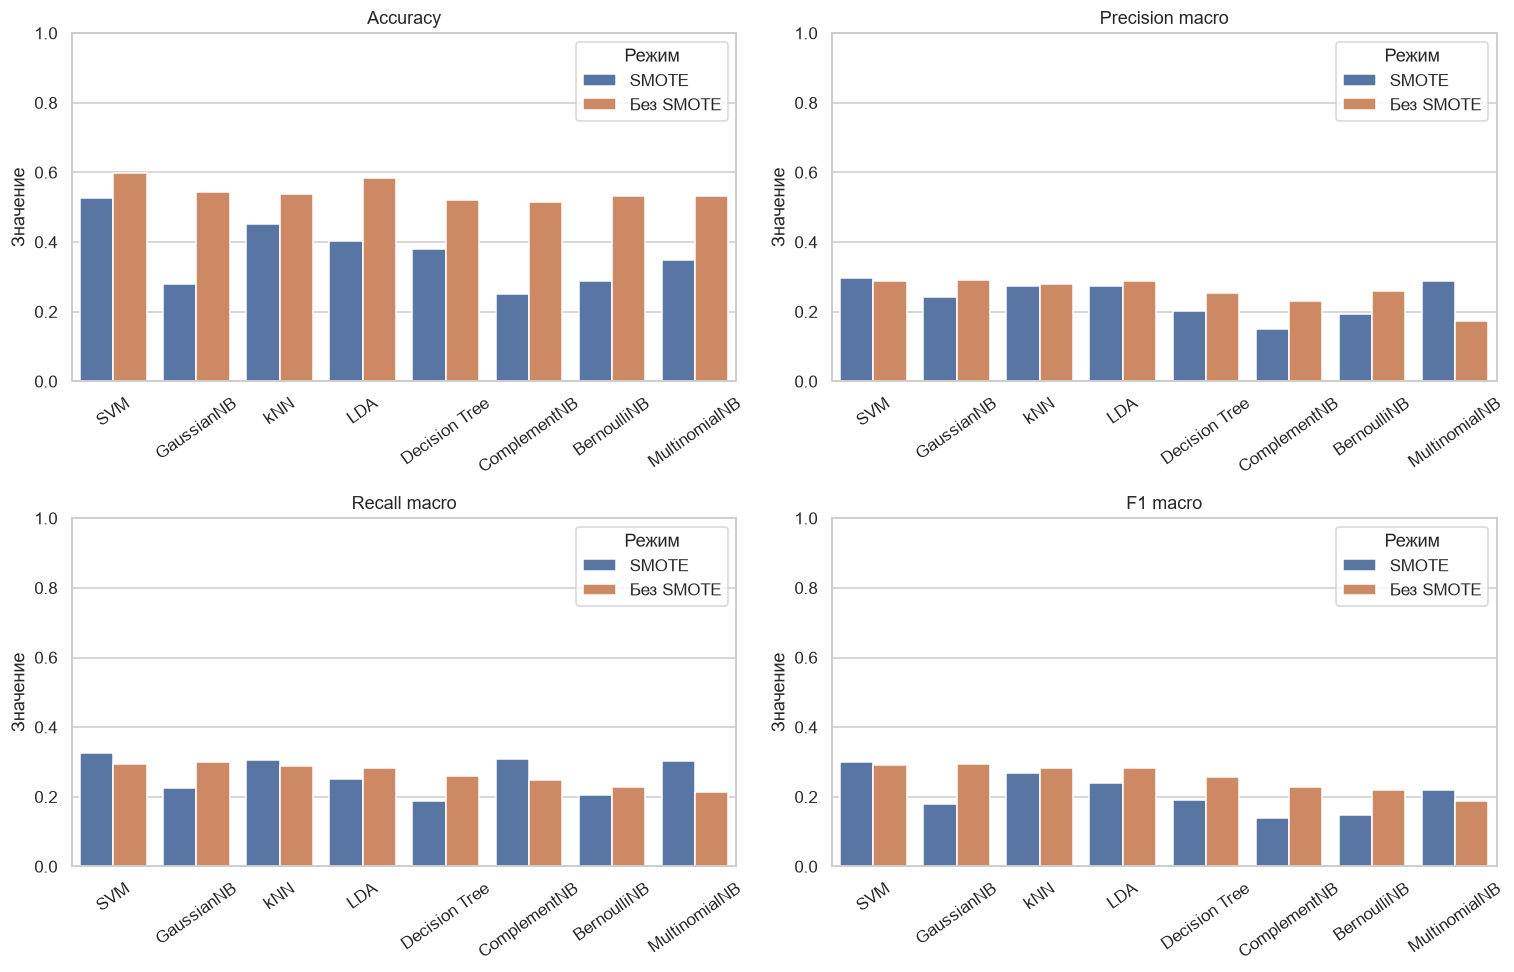

Лучший результат по тестовому macro F1:


,Алгоритм,Режим,Accuracy,F1 macro,AUC ROC OvR macro
0,SVM,SMOTE,0.525735,0.299533,0.70059


In [8]:
metric_cols=['Accuracy','Precision macro','Recall macro','F1 macro']
fig,axs=plt.subplots(2,2,figsize=(14,9))
for ax,metric in zip(axs.flat,metric_cols):
    sns.barplot(data=results,x='Алгоритм',y=metric,hue='Режим',ax=ax)
    ax.tick_params(axis='x',rotation=35); ax.set_ylim(0,1)
    ax.set(title=metric,xlabel='',ylabel='Значение')
plt.tight_layout();plt.show()
print('Лучший результат по тестовому macro F1:')
display(results.head(1)[['Алгоритм','Режим','Accuracy','F1 macro','AUC ROC OvR macro']])

**Интерпретация:** сравнивать одну Accuracy недостаточно: распространённые классы могут обеспечивать высокий общий результат даже при низкой полноте редких классов. Для равноправного учёта классов используем macro-усреднение.

## 6. Матрица ошибок, отчёт о классификации и ROC-кривые

Модель, выбранная по CV F1 macro: ('GaussianNB', 'Без SMOTE')
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.12      0.18      0.15        11
           5       0.68      0.63      0.65       116
           6       0.58      0.54      0.56       107
           7       0.37      0.45      0.41        33
           8       0.00      0.00      0.00         3

    accuracy                           0.54       272
   macro avg       0.29      0.30      0.29       272
weighted avg       0.57      0.54      0.55       272



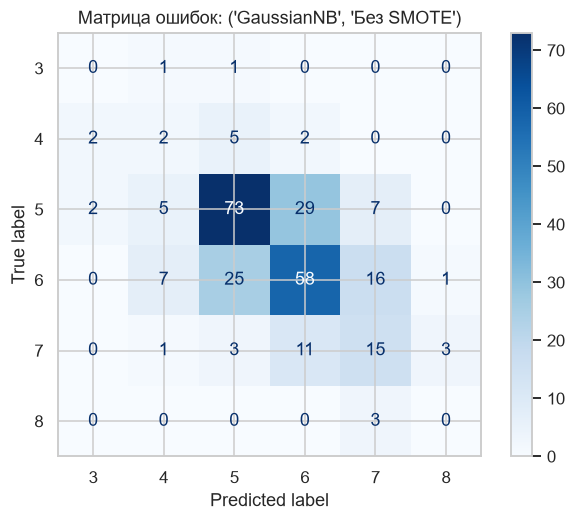

In [9]:
best_row=results.sort_values('CV F1 macro',ascending=False).iloc[0]
best_key=(best_row['Алгоритм'],best_row['Режим'])
best_pred=test_predictions[best_key]
print('Модель, выбранная по CV F1 macro:',best_key)
print(classification_report(y_test,best_pred,labels=classes,zero_division=0))
fig,ax=plt.subplots(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(y_test,best_pred,labels=classes,cmap='Blues',ax=ax)
ax.set_title('Матрица ошибок: '+str(best_key));plt.show()

**Как читать матрицу:** строки — истинные классы, столбцы — предсказанные; диагональ — верные ответы. Например, строка 5, столбец 6 — вина качества 5, ошибочно отнесённые к качеству 6. При редких классах смотрите именно Recall по строкам.

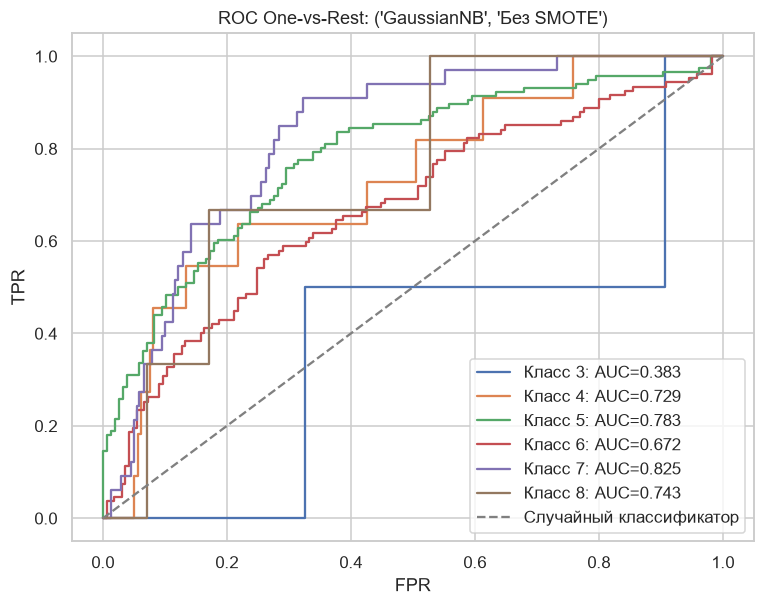

Общая ROC-AUC OvR macro: 0.6893


In [10]:
fig,ax=plt.subplots(figsize=(8,6))
y_bin=label_binarize(y_test,classes=classes)
prob=test_probabilities[best_key]
for j,cls in enumerate(classes):
    if len(np.unique(y_bin[:,j]))<2:continue
    fpr,tpr,thresholds=roc_curve(y_bin[:,j],prob[:,j])
    ax.plot(fpr,tpr,label=f'Класс {cls}: AUC={auc(fpr,tpr):.3f}')
ax.plot([0,1],[0,1],'--',color='gray',label='Случайный классификатор')
ax.set(xlabel='FPR',ylabel='TPR',title='ROC One-vs-Rest: '+str(best_key))
ax.legend();plt.show()
print('Общая ROC-AUC OvR macro:',round(float(best_row['AUC ROC OvR macro']),4))

**Вывод:** каждая ROC-кривая рассматривает один класс как положительный, а остальные как отрицательные (OvR). ROC строится **по вероятностям**, а не по итоговым меткам. AUC около 0.5 означает слабое ранжирование, ближе к 1 — хорошее. Для дисбаланса также важны PR-кривые и per-class Recall.

## 7. Изучение влияния параметров дерева решений

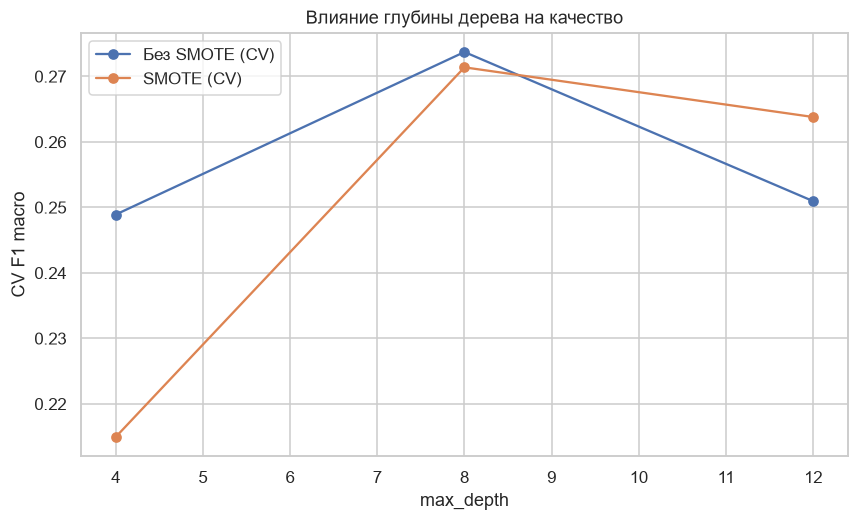

Глубина обученного дерева: 12 | Листьев: 223


,Важность признака
alcohol,0.193516
sulphates,0.141985
volatile acidity,0.139833
total sulfur dioxide,0.102220
pH,0.074594
chlorides,0.070828
free sulfur dioxide,0.070365
residual sugar,0.064136
citric acid,0.053821
fixed acidity,0.053419


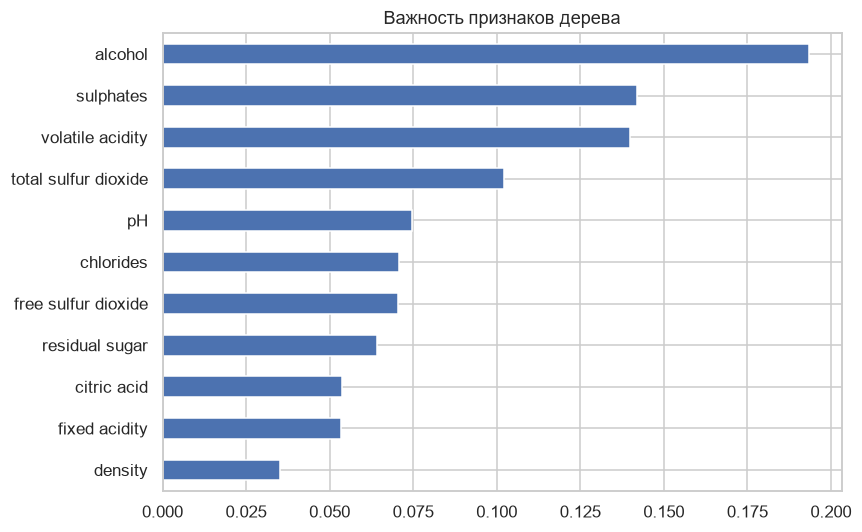

In [11]:
fig,ax=plt.subplots(figsize=(9,5))
for mode in ['Без SMOTE','SMOTE']:
    search=searches[('Decision Tree',mode)]
    r=pd.DataFrame(search.cv_results_)
    r=r[(r['param_model__criterion']=='gini') & (r['param_model__min_samples_leaf']==2)]
    r=r.sort_values('param_model__max_depth')
    ax.plot(r['param_model__max_depth'].astype(int),r['mean_test_score'],marker='o',label=mode+' (CV)')
ax.set(xlabel='max_depth',ylabel='CV F1 macro',title='Влияние глубины дерева на качество')
ax.legend();plt.show()
model_tree=searches[('Decision Tree','Без SMOTE')].best_estimator_.named_steps['model']
print('Глубина обученного дерева:',model_tree.get_depth(),'| Листьев:',model_tree.get_n_leaves())
imp=pd.Series(model_tree.feature_importances_,index=X.columns).sort_values(ascending=False)
display(imp.rename('Важность признака').to_frame())
imp.sort_values().plot.barh(figsize=(8,5),title='Важность признаков дерева');plt.tight_layout();plt.show()

**Объяснение:** большая глубина позволяет строить более сложные правила и потенциально переобучаться; слишком малая глубина может приводить к недообучению. Важности дерева показывают, насколько его разбиения опирались на признаки, но не доказывают причинное влияние.

## 8. Нейронная сеть TensorFlow/Keras — обязательная часть

Мы обучаем **четыре конфигурации** полносвязной сети с ReLU и Softmax. Для честной настройки Train ещё раз разделяется на внутренние train/validation; Test не используется для выбора нейросети. Для каждой конфигурации записываются история и логи TensorBoard.

**Почему `sparse_categorical_crossentropy`?** Классы переводятся из 3–8 в индексы 0–5, а не в one-hot-векторы. На выходе 6 нейронов с softmax, так как это многоклассовая классификация.

In [12]:
tf.keras.backend.clear_session()
X_inner,X_val,y_inner,y_val=train_test_split(X_train,y_train,test_size=0.2,
                            random_state=SEED,stratify=y_train)
# scaler обучаем только на внутренней train, validation и test трансформируем
nn_scaler=StandardScaler()
X_inner_std=nn_scaler.fit_transform(X_inner).astype('float32')
X_val_std=nn_scaler.transform(X_val).astype('float32')
X_test_std=nn_scaler.transform(X_test).astype('float32')
label_to_idx={int(v):i for i,v in enumerate(classes)}
y_inner_idx=np.array([label_to_idx[int(v)] for v in y_inner],dtype='int32')
y_val_idx=np.array([label_to_idx[int(v)] for v in y_val],dtype='int32')
print('Внутренний train:',X_inner_std.shape,'Validation:',X_val_std.shape,'Test:',X_test_std.shape)
print('Индексы классов:',label_to_idx)


Внутренний train: (869, 11) Validation: (218, 11) Test: (272, 11)
Индексы классов: {3: 0, 4: 1, 5: 2, 6: 3, 7: 4, 8: 5}


**Вывод:** тест остаётся неизменным. Модель нейросети видит только внутренний train, а критерии выбора архитектуры вычисляются по validation.

In [13]:
def build_nn(hidden=(32,16),dropout=0.2,lr=0.001):
    inputs=tf.keras.Input(shape=(X.shape[1],),name='chemical_features')
    h=inputs
    for units in hidden:
        h=tf.keras.layers.Dense(units,activation='relu')(h)
        if dropout:
            h=tf.keras.layers.Dropout(dropout)(h)
    outputs=tf.keras.layers.Dense(len(classes),activation='softmax',name='wine_quality')(h)
    model=tf.keras.Model(inputs,outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model
example_nn=build_nn()
example_nn.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ chemical_features (InputLayer)  │ (None, 11)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ wine_quality (Dense)            │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,014 (3.96 KB)

 Trainable params: 1,014 (3.96 KB)

 Non-trainable params: 0 (0.00 B)

**Разбор архитектуры:** `Input(shape=(11,))` принимает химические признаки; `Dense` формируют полносвязные слои; `ReLU` добавляет нелинейность; `Dropout` уменьшает риск переобучения; финальный `Dense(6, softmax)` выдаёт шесть вероятностей с суммой 1. `summary()` показывает количество параметров.

In [14]:
NN_CONFIGS=[
  {'name':'MLP_16_noSMOTE','hidden':(16,),'dropout':0.0,'lr':0.001,'smote':False,'batch':32},
  {'name':'MLP_32_16_noSMOTE','hidden':(32,16),'dropout':0.2,'lr':0.001,'smote':False,'batch':32},
  {'name':'MLP_32_16_SMOTE','hidden':(32,16),'dropout':0.2,'lr':0.001,'smote':True,'batch':32},
  {'name':'MLP_64_32_SMOTE','hidden':(64,32),'dropout':0.3,'lr':0.0005,'smote':True,'batch':32},
]
from datetime import datetime
log_root=(Path.cwd()/'tensorboard_logs'/'wine_lab2').resolve()
log_root.mkdir(parents=True,exist_ok=True)
run_tag=datetime.now().strftime('%Y%m%d_%H%M%S')
NN_MODELS={}; NN_HISTORY={}; NN_RESULTS=[]
for cfg in NN_CONFIGS:
    print('\n==== Обучение:',cfg['name'],'====')
    tf.keras.utils.set_random_seed(SEED)
    tf.keras.backend.clear_session()
    model=build_nn(cfg['hidden'],cfg['dropout'],cfg['lr'])
    if cfg['smote']:
        xx,yy=SMOTE(k_neighbors=3,random_state=SEED).fit_resample(X_inner_std,y_inner_idx)
        xx=np.asarray(xx,dtype='float32'); yy=np.asarray(yy,dtype='int32')
    else:
        xx,yy=X_inner_std,y_inner_idx
    logdir=log_root/(run_tag+'_'+cfg['name'])
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=12,
                                         restore_best_weights=True),
        tf.keras.callbacks.TensorBoard(log_dir=str(logdir),histogram_freq=0)
    ]
    history=model.fit(xx,yy,validation_data=(X_val_std,y_val_idx),
                      epochs=65,batch_size=cfg['batch'],verbose=0,callbacks=callbacks)
    val_proba=model.predict(X_val_std,verbose=0)
    val_pred=val_proba.argmax(axis=1)
    NN_MODELS[cfg['name']]=model
    NN_HISTORY[cfg['name']]=history.history
    NN_RESULTS.append({'Конфигурация':cfg['name'],'SMOTE':cfg['smote'],
                       'Скрытые слои':str(cfg['hidden']),'Dropout':cfg['dropout'],
                       'Learning rate':cfg['lr'],'Epochs':len(history.history['loss']),
                       'Val Accuracy':accuracy_score(y_val_idx,val_pred),
                       'Val F1 macro':f1_score(y_val_idx,val_pred,average='macro',zero_division=0),
                       'Min val_loss':min(history.history['val_loss']),
                       'TensorBoard log':str(logdir)})
    print('Эпох:',len(history.history['loss']),'Val macro F1:',round(NN_RESULTS[-1]['Val F1 macro'],4),
          '| Лучший val_loss:',round(NN_RESULTS[-1]['Min val_loss'],4))
nn_table=pd.DataFrame(NN_RESULTS).sort_values('Val F1 macro',ascending=False)
display(nn_table.round(4))


==== Обучение: MLP_16_noSMOTE ====
Эпох: 65 Val macro F1: 0.3476 | Лучший val_loss: 0.9505

==== Обучение: MLP_32_16_noSMOTE ====

Эпох: 65 Val macro F1: 0.3146 | Лучший val_loss: 0.9213

==== Обучение: MLP_32_16_SMOTE ====
Эпох: 39 Val macro F1: 0.2998 | Лучший val_loss: 1.2447

==== Обучение: MLP_64_32_SMOTE ====
Эпох: 53 Val macro F1: 0.277 | Лучший val_loss: 1.2266


,Конфигурация,SMOTE,Скрытые слои,Dropout,Learning rate,Epochs,Val Accuracy,Val F1 macro,Min val_loss,TensorBoard log
0,MLP_16_noSMOTE,False,"(16,)",0.0,0.0010,65,0.6284,0.3476,0.9505,C:\Users\Perfect_Player\Downloads\_D0_9B_D0_A0...
1,MLP_32_16_noSMOTE,False,"(32, 16)",0.2,0.0010,65,0.6376,0.3146,0.9213,C:\Users\Perfect_Player\Downloads\_D0_9B_D0_A0...
2,MLP_32_16_SMOTE,True,"(32, 16)",0.2,0.0010,39,0.4128,0.2998,1.2447,C:\Users\Perfect_Player\Downloads\_D0_9B_D0_A0...
3,MLP_64_32_SMOTE,True,"(64, 32)",0.3,0.0005,53,0.4404,0.2770,1.2266,C:\Users\Perfect_Player\Downloads\_D0_9B_D0_A0...


**Интерпретация:** сравниваем архитектуры по **валидационной macro F1**, потому что классы несбалансированы. `EarlyStopping` останавливает обучение при отсутствии улучшения `val_loss` и восстанавливает лучшие веса. Каждая конфигурация имеет отдельный каталог TensorBoard. Балансировка выполняется только на внутреннем Train.

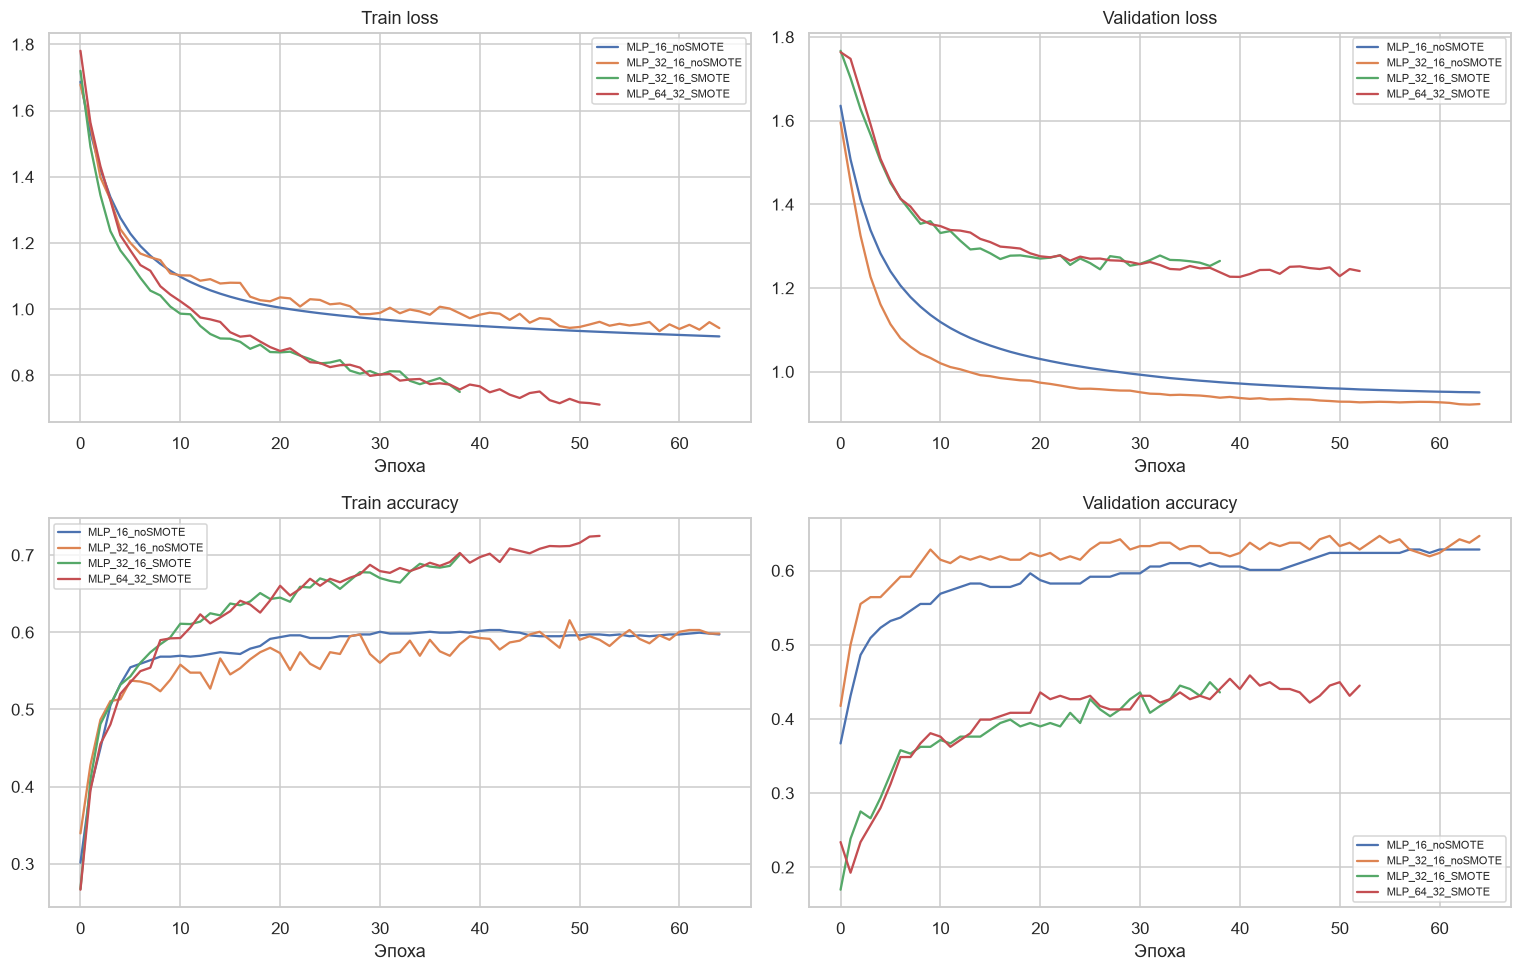

In [15]:
fig,axes=plt.subplots(2,2,figsize=(14,9))
for cfg in NN_CONFIGS:
    name=cfg['name']; hist=NN_HISTORY[name]
    axes[0,0].plot(hist['loss'],label=name)
    axes[0,1].plot(hist['val_loss'],label=name)
    axes[1,0].plot(hist['accuracy'],label=name)
    axes[1,1].plot(hist['val_accuracy'],label=name)
for ax,title in zip(axes.flat,['Train loss','Validation loss','Train accuracy','Validation accuracy']):
    ax.set(title=title,xlabel='Эпоха');ax.legend(fontsize=7)
plt.tight_layout();plt.show()

**Как объяснять графики:** снижение train loss означает, что модель лучше подстраивается под тренировочные данные. Если train loss продолжает падать, а val loss растёт — возможное переобучение. При одновременно высоких ошибках и низком качестве — возможное недообучение. Сравнение экспериментов помогает выбрать архитектуру, но финальная оценка проводится только на Test.

### 8.1. Подтверждение обучения через TensorBoard

TensorBoard записывает данные обучения через callback `tf.keras.callbacks.TensorBoard`. В отличие от интерактивного веб-интерфейса, **встроенные ниже снимки экрана сохраняются непосредственно внутри `.ipynb` и видны на GitHub без запуска TensorFlow**. Это реальные скриншоты запусков лабораторной, сделанные после обучения на компьютере автора.

На снимках показаны несколько запусков экспериментов (поэтому часть линий повторяется). Они позволяют проверить динамику `loss`, `accuracy`, `learning_rate` и отдельно валидационные метрики на итерациях. Сохранённые выше графики Matplotlib построены непосредственно из истории обучения Keras.

In [16]:
# Проверка фактических журналов TensorBoard.
# На GitHub сохраняется предыдущий вывод: подтверждено 16 файлов событий
# в ранее выполненной версии этого ноутбука (Windows, 2 ноября 2026 г.).
from pathlib import Path
log_root = (Path.cwd() / "tensorboard_logs" / "wine_lab2").resolve()
event_files = sorted(log_root.rglob("events.out.tfevents.*"))
print("Каталог журналов:", log_root)
print("Файлов событий:", len(event_files))
print("Эксперименты:", ", ".join(sorted({f.parent.parent.name for f in event_files})))
if not event_files:
    print("На новом компьютере журналы будут созданы при повторном обучении.")


Каталог журналов: C:\Users\Perfect_Player\Downloads\_D0_9B_D0_A02_Wine_SMOTE_TensorBoard__D0_92_D0_9D_D0_A3_D0_A2_D0_A0_D0_98_NOTEBOOK__D0_9A_D0_9E_D0_9C_D0_9F_D0_9B_D0_95_D0_9A_D0_A2\tensorboard_logs\wine_lab2
Файлов событий: 16
Эксперименты: 20261102_170839_MLP_16_noSMOTE, 20261102_170839_MLP_32_16_SMOTE, 20261102_170839_MLP_32_16_noSMOTE, 20261102_170839_MLP_64_32_SMOTE, 20261102_171035_MLP_16_noSMOTE, 20261102_171035_MLP_32_16_SMOTE, 20261102_171035_MLP_32_16_noSMOTE, 20261102_171035_MLP_64_32_SMOTE


### 8.2. Скриншоты настоящего TensorBoard

Ниже встроены **пять реальных скриншотов TensorBoard**. Они являются иллюстрацией результатов выполнения, а не программно сгенерированными примерами. Папка `tensorboard_logs` **не требуется** для просмотра этих изображений в ноутбуке или на GitHub.

На диаграммах присутствуют несколько серий запусков, поэтому для интерпретации следует сравнивать линии одного и того же запуска и отдельно отслеживать `train` и `validation`.

#### 1. epoch_loss — функция потерь по эпохам

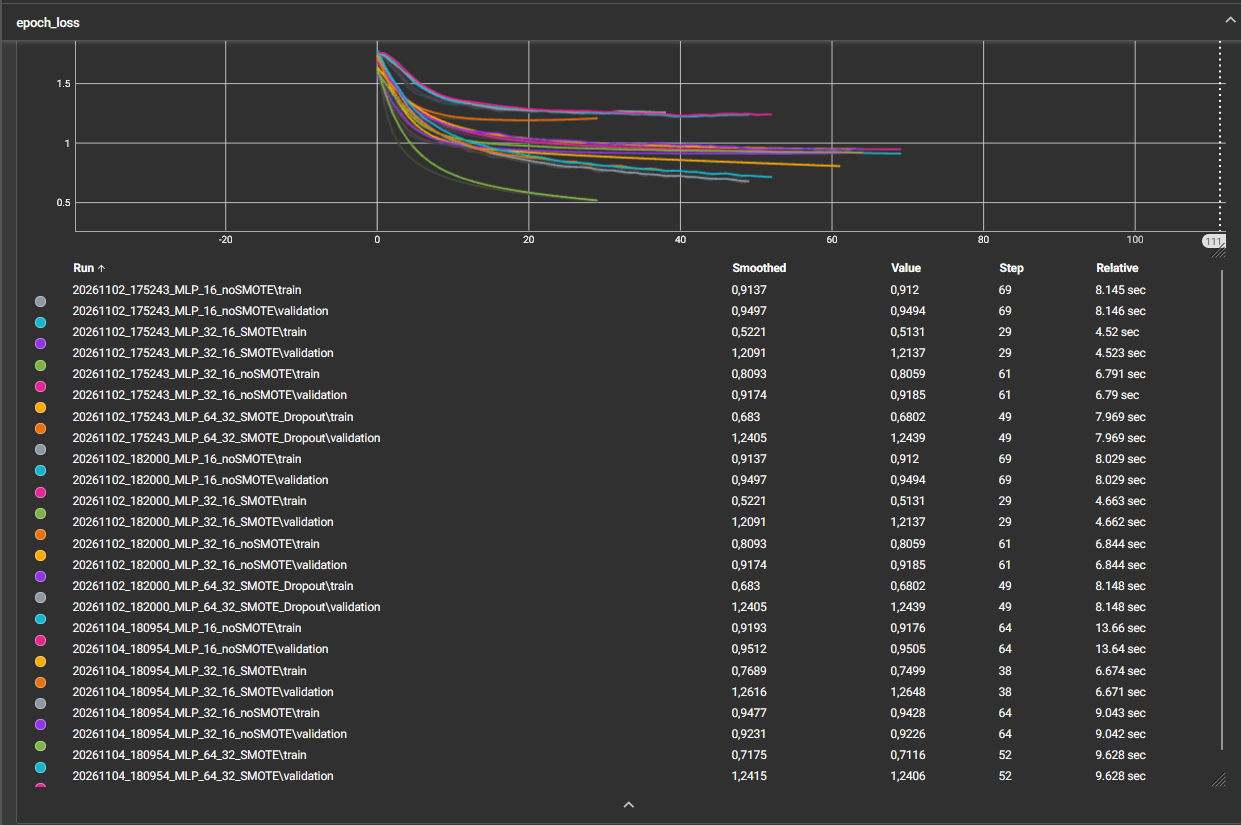

**Анализ.** У всех моделей функция потерь на Train уменьшается. Для моделей со SMOTE в показанных запусках значение Validation Loss заметно выше, чем у вариантов без SMOTE. Это говорит, что балансировка не гарантирует лучшей обобщающей способности; вывод подтверждается только для проверенных конфигураций.

#### 2. epoch_accuracy — точность классификации по эпохам

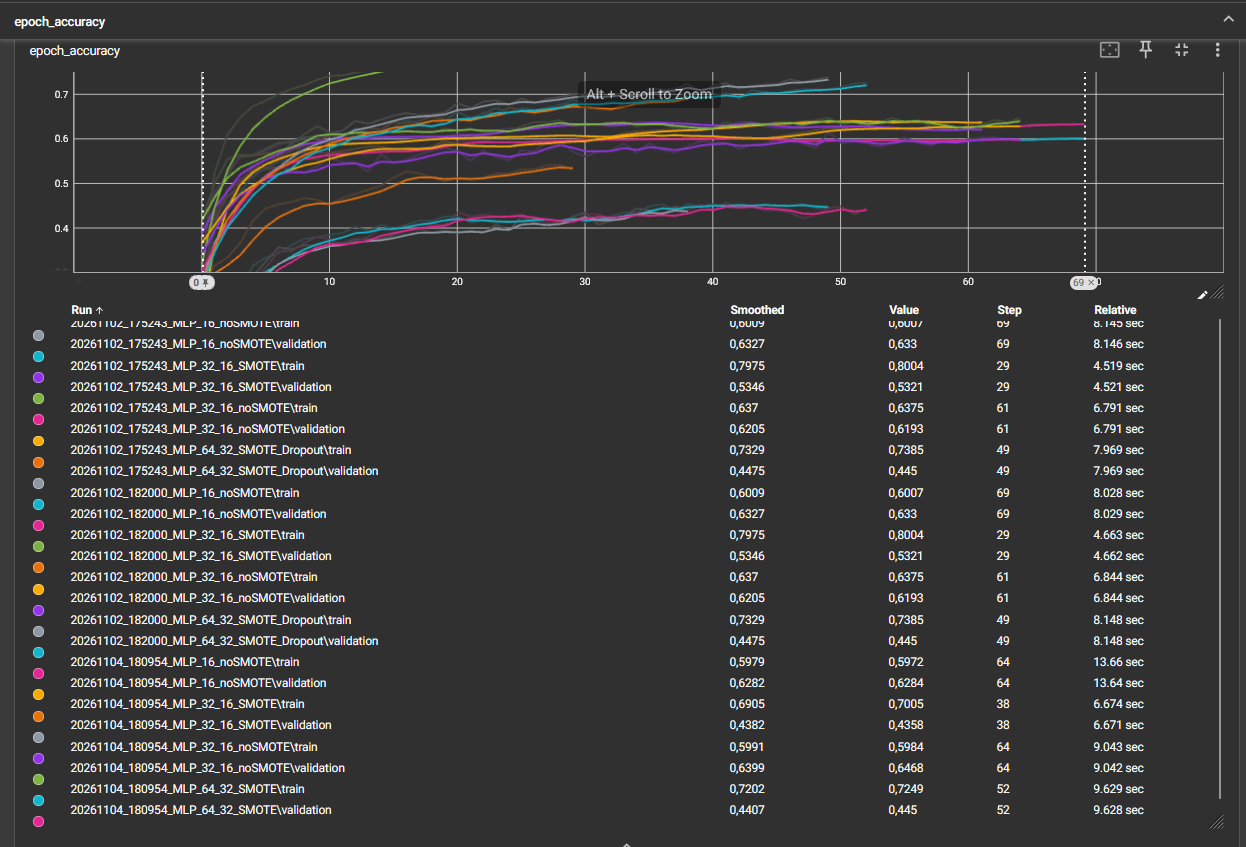

**Анализ.** Точность на Train растёт. Валидационная Accuracy моделей без SMOTE в показанных запусках около 0,63–0,65, а у моделей со SMOTE — примерно 0,44–0,53. Этот результат относится к общей Accuracy: для редких классов дополнительно необходимо анализировать F1 macro и матрицы ошибок.

#### 3. epoch_learning_rate — скорость обучения

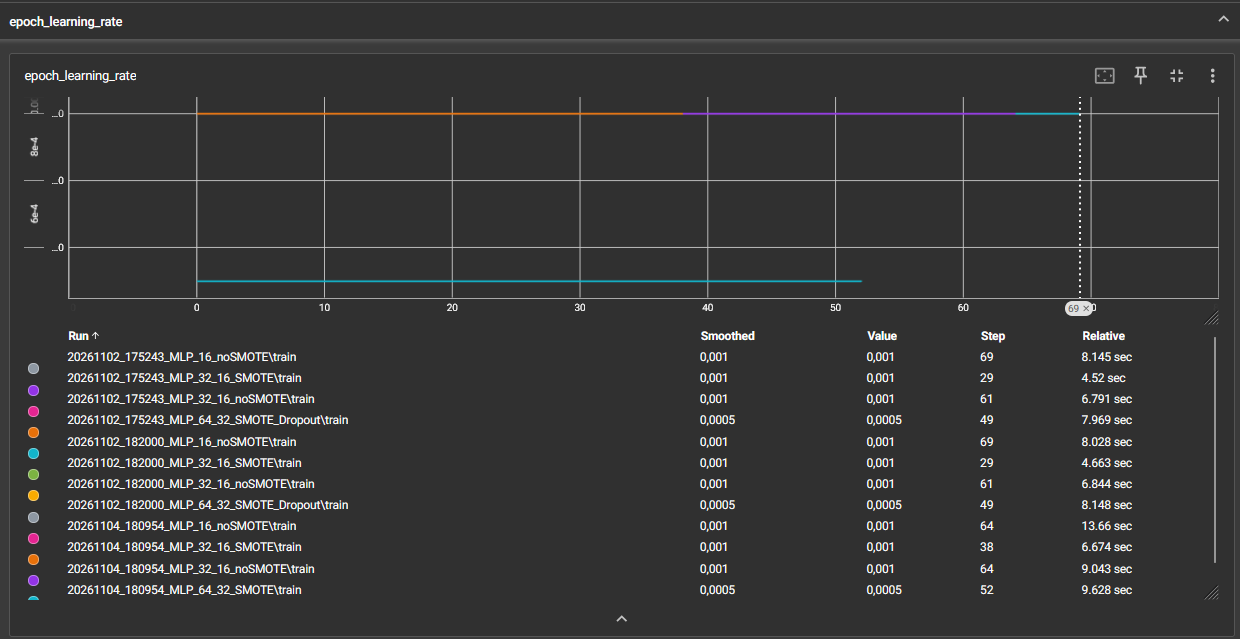

**Анализ.** Зафиксированы постоянные learning rate: 0,001 для большинства архитектур и 0,0005 для более крупной модели. Постоянные линии ожидаемы: в этих экспериментах автоматическое изменение learning rate не задавалось.

#### 4. evaluation_accuracy_vs_iterations — валидационная Accuracy по шагам

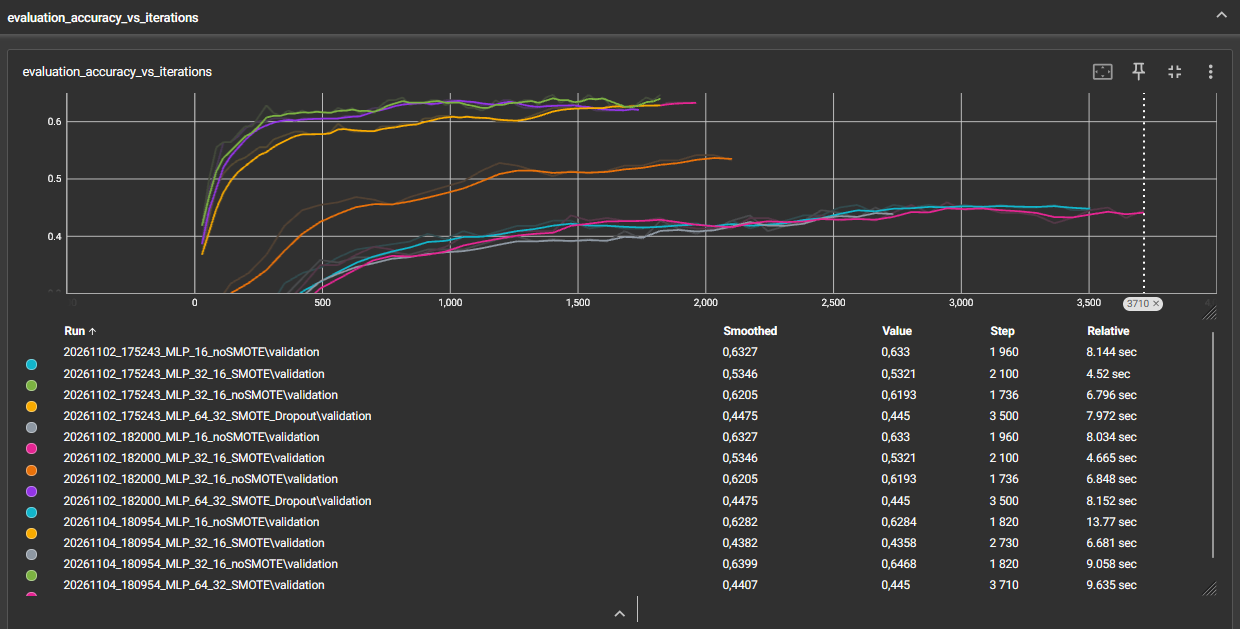

**Анализ.** Эти кривые показывают изменение валидационной точности не по эпохам, а по шагам (итерациям). Разная длина линий обусловлена разным числом шагов и длительностью обучения.

#### 5. evaluation_loss_vs_iterations — валидационная ошибка по шагам

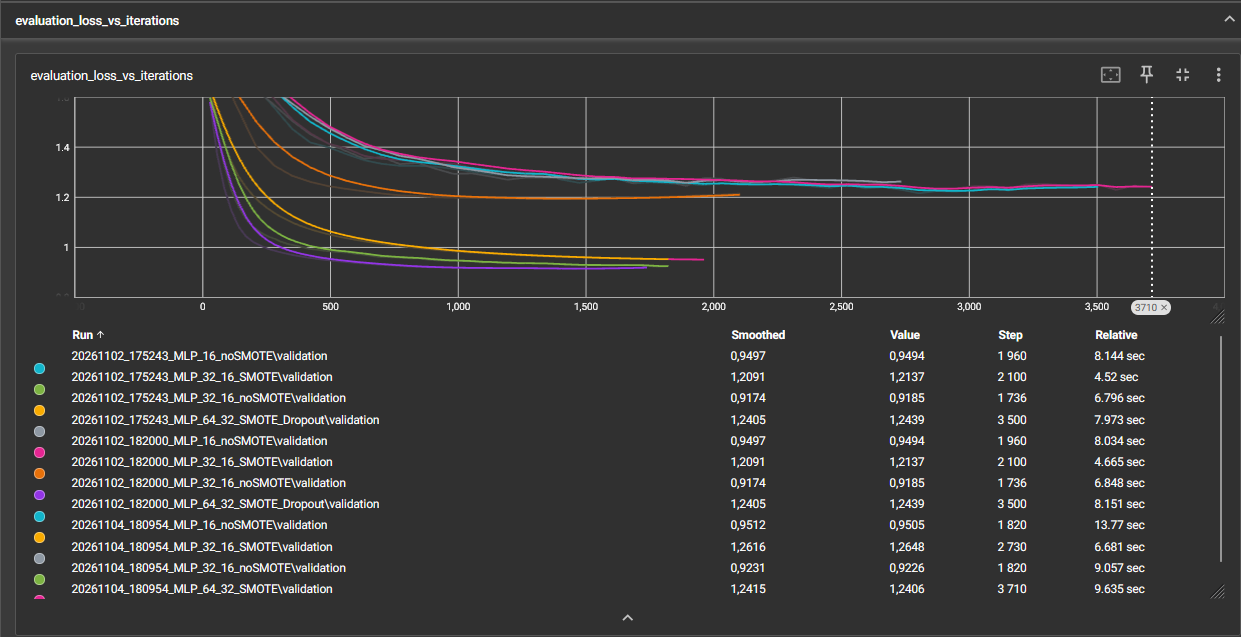

**Анализ.** У большинства запусков валидационная ошибка сначала уменьшается, затем приближается к плато. Для отдельных кривых дальнейшее обучение почти не улучшает результат; это одна из причин применять EarlyStopping.

**Вывод по TensorBoard.** На скриншотах подтверждены реальные записи TensorBoard по всем четырём конфигурациям нейросети. Кривые потерь и точности, а также заданные значения learning rate позволяют сопоставить модели на Train и Validation. В показанных запусках варианты без SMOTE чаще демонстрируют лучшую валидационную Accuracy и меньший Validation Loss; при этом вывод о лучшей модели делается по заранее выбранной метрике F1 macro, а тестовая выборка используется только для итоговой проверки. Скриншоты встроены в Markdown-ячейки notebook, поэтому отдельная папка логов на GitHub не нужна.

## 9. Итоговая оценка лучшей нейросети на независимом Test

Выбранная по validation F1 модель: MLP_16_noSMOTE
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.63      0.77      0.69       116
           6       0.56      0.57      0.57       107
           7       0.57      0.36      0.44        33
           8       0.00      0.00      0.00         3

    accuracy                           0.60       272
   macro avg       0.29      0.28      0.28       272
weighted avg       0.56      0.60      0.57       272



,Алгоритм,Режим,Accuracy,Precision macro,Recall macro,F1 macro,AUC ROC OvR macro
0,TensorFlow MLP,MLP_16_noSMOTE,0.5956,0.2938,0.2835,0.2836,0.735


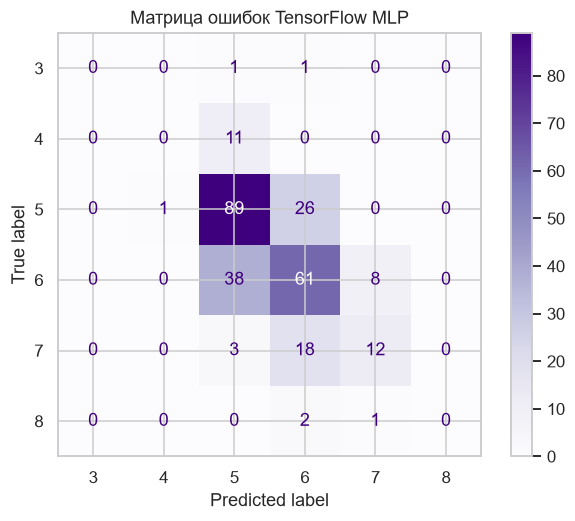

In [17]:
best_nn_name=nn_table.iloc[0]['Конфигурация']
best_nn=NN_MODELS[best_nn_name]
proba_nn=best_nn.predict(X_test_std,verbose=0)
idx_nn=np.argmax(proba_nn,axis=1)
pred_nn=classes[idx_nn]
print('Выбранная по validation F1 модель:',best_nn_name)
print(classification_report(y_test,pred_nn,labels=classes,zero_division=0))
auc_nn=roc_auc_score(y_test,proba_nn,labels=classes,multi_class='ovr',average='macro')
metric_nn={'Алгоритм':'TensorFlow MLP','Режим':best_nn_name,
           'Accuracy':accuracy_score(y_test,pred_nn),
           'Precision macro':precision_score(y_test,pred_nn,average='macro',zero_division=0),
           'Recall macro':recall_score(y_test,pred_nn,average='macro',zero_division=0),
           'F1 macro':f1_score(y_test,pred_nn,average='macro',zero_division=0),
           'AUC ROC OvR macro':auc_nn}
display(pd.DataFrame([metric_nn]).round(4))
fig,ax=plt.subplots(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(y_test,pred_nn,labels=classes,ax=ax,cmap='Purples')
ax.set_title('Матрица ошибок TensorFlow MLP');plt.show()

**Объяснение:** выбор архитектуры производится **без подсматривания в Test**. `predict()` выдаёт вероятности, `argmax` выбирает индекс, `classes[idx]` возвращает исходную метку качества. Итоговые метрики и матрица ошибок рассчитываются на исходном тестовом распределении.

,Алгоритм,Режим,Accuracy,Precision macro,Recall macro,F1 macro,AUC ROC OvR macro
0,SVM,SMOTE,0.5257,0.2958,0.3244,0.2995,0.7006
1,GaussianNB,Без SMOTE,0.5441,0.2922,0.3013,0.2948,0.6893
2,SVM,Без SMOTE,0.5993,0.2892,0.2930,0.2903,0.8016
16,TensorFlow MLP,MLP_16_noSMOTE,0.5956,0.2938,0.2835,0.2836,0.7350
3,kNN,Без SMOTE,0.5368,0.2806,0.2878,0.2824,0.6394
4,LDA,Без SMOTE,0.5846,0.2868,0.2828,0.2822,0.7757
5,kNN,SMOTE,0.4522,0.2726,0.3052,0.2673,0.6169
6,Decision Tree,Без SMOTE,0.5221,0.2532,0.2611,0.2569,0.5637
7,LDA,SMOTE,0.4044,0.2737,0.2503,0.2404,0.7203
8,ComplementNB,Без SMOTE,0.5147,0.2316,0.2485,0.2288,0.7151


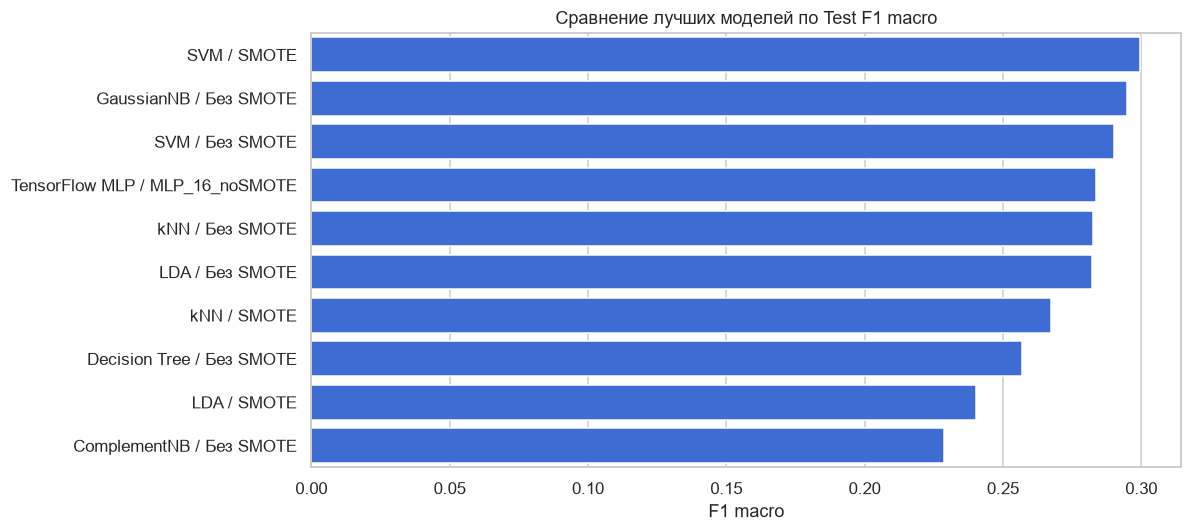

In [18]:
comparison=pd.concat([results[['Алгоритм','Режим','Accuracy','Precision macro','Recall macro','F1 macro','AUC ROC OvR macro']],
                      pd.DataFrame([metric_nn])],ignore_index=True)
display(comparison.sort_values('F1 macro',ascending=False).round(4))
fig,ax=plt.subplots(figsize=(11,5))
top=comparison.sort_values('F1 macro',ascending=False).head(10).copy()
top['Модель']=top['Алгоритм']+' / '+top['Режим']
sns.barplot(data=top,x='F1 macro',y='Модель',ax=ax,color='#2563eb')
ax.set(title='Сравнение лучших моделей по Test F1 macro',xlabel='F1 macro',ylabel='')
plt.tight_layout();plt.show()

## 10. Итоговые выводы

1. Признаки вина позволяют решать **многоклассовую классификацию**, однако метки распределены неравномерно.
2. SMOTE устраняет численный дисбаланс в **обучающей** выборке, но его влияние на метрики определяется экспериментально и может быть неоднозначным.
3. Наивный Байес, дерево решений, LDA, SVM и kNN сравниваются на одинаковом Test, а гиперпараметры выбираются с помощью CV.
4. Для дисбаланса помимо Accuracy важна macro F1 и метрики каждого класса.
5. Нейросеть TensorFlow/Keras изучается в четырёх конфигурациях; история обучения и TensorBoard позволяют анализировать переобучение и влияние learning rate, Dropout, архитектуры и SMOTE.
6. Итоговый вывод о лучшей модели делается на основе **фактически полученной** таблицы сравнения выше, без предварительных предположений о победителе.

**Для защиты:** покажите преподавателю графики классов, матрицу ошибок, сравнительную таблицу, `model.summary()`, четыре кривые обучения и TensorBoard с двумя экспериментами.

**TensorBoard:** запускается автоматически после обучения из абсолютного каталога логов. Для GitHub в ячейке 8.1 предусмотрена вставка реального скриншота из буфера обмена. Для защиты сохраните ноутбук после запуска всех ячеек, чтобы в нём остались ваши результаты.